## Numerical PDE Methods

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags_array
from scipy.sparse.linalg import factorized

### Problem 1:

Consider $u_t = u_{xx}$ for $x \in (0,10)$

With following BC and IC: $u(x,0)=0$, $u(0,t)=\text{sin}(t)$, $u(10,t)=0$

Use space step sizes of $\Delta x = 0.1, 0.05$ with second order finite differences, and suitably chosen $\Delta t$.

All examples below run to $T=10$: 4000 time steps for $dx=0.1$ and
16000 for $dx=0.05$, keeping $dt=dx^2/4$. Each example shows 12 snapshots
and a heatmap with the same color range $[-1,1]$: blue is negative,
white is zero, and red is positive.


In [2]:
def plot_heat(x, times, U, title):
    """Show twelve time snapshots and an x-t heatmap."""
    indices = np.linspace(0, len(times) - 1, 12, dtype=int)
    fig, axes = plt.subplots(
        3, 4, figsize=(14, 9), sharex=True, sharey=True,
        constrained_layout=True,
    )

    for ax, k in zip(axes.flat, indices):
        ax.plot(x, U[k], linewidth=1.5)
        ax.set_title(f"t = {times[k]:.4g}")
        ax.set_xlabel("x")
        ax.set_ylabel("u(x, t)")
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    heatmap = ax.imshow(
        U, origin="lower", aspect="auto", interpolation="nearest",
        extent=[x[0], x[-1], times[0], times[-1]],
        cmap="RdBu_r", vmin=-1, vmax=1,
    )
    ax.set_xlim(x[0], x[-1])
    ax.set_ylim(times[0], times[-1])
    ax.set_xlabel("x")
    ax.set_ylabel("t")
    ax.set_title(title)
    fig.colorbar(heatmap, ax=ax, label="u(x, t)")
    plt.show()


def solve_heat(dx, method="explicit", steps=8000, dt=None, l=10,
               alpha=np.sin, beta=lambda t: 0.0, plot=True):
    """Solve u_t = u_xx with zero initial data; return x, times, U."""
    if method not in ("explicit", "implicit"):
        raise ValueError("method must be 'explicit' or 'implicit'")

    if dt is None:
        dt = dx**2 / 4
    n = int(round(l / dx)) - 1
    mu = dt / dx**2
    u = np.zeros(n)

    b = lambda t: mu * np.concatenate(
        ([alpha(t)], np.zeros(n - 2), [beta(t)])
    )

    if method == "explicit":
        A = diags_array(
            [np.full(n - 1, mu), np.full(n, 1 - 2*mu), np.full(n - 1, mu)],
            offsets=[-1, 0, 1], shape=(n, n), format="csr",
        )
    else:
        A = diags_array(
            [np.full(n - 1, -mu), np.full(n, 1 + 2*mu), np.full(n - 1, -mu)],
            offsets=[-1, 0, 1], shape=(n, n), format="csc",
        )
        solve = factorized(A)

    results = [u.copy()]
    for i in range(steps):
        if method == "explicit":
            u = A @ u + b(i * dt)
        else:
            u = solve(u + b((i + 1) * dt))
        results.append(u)

    x = np.linspace(0, l, n + 2)
    times = np.arange(steps + 1) * dt
    U = np.column_stack([
        [alpha(t) for t in times],
        np.asarray(results),
        [beta(t) for t in times],
    ])

    if plot:
        label = "Explicit method" if method == "explicit" else "Implicit method (backward Euler)"
        title = f"{label} | {steps} time steps | dx = {dx:.4g}, dt = {dt:.4g} | T = {times[-1]:.4g}"
        plot_heat(x, times, U, title)

    return x, times, U


#### Explicit Method:
$\Delta t \leq \frac{(\Delta x)^2}{2}$ for stability.

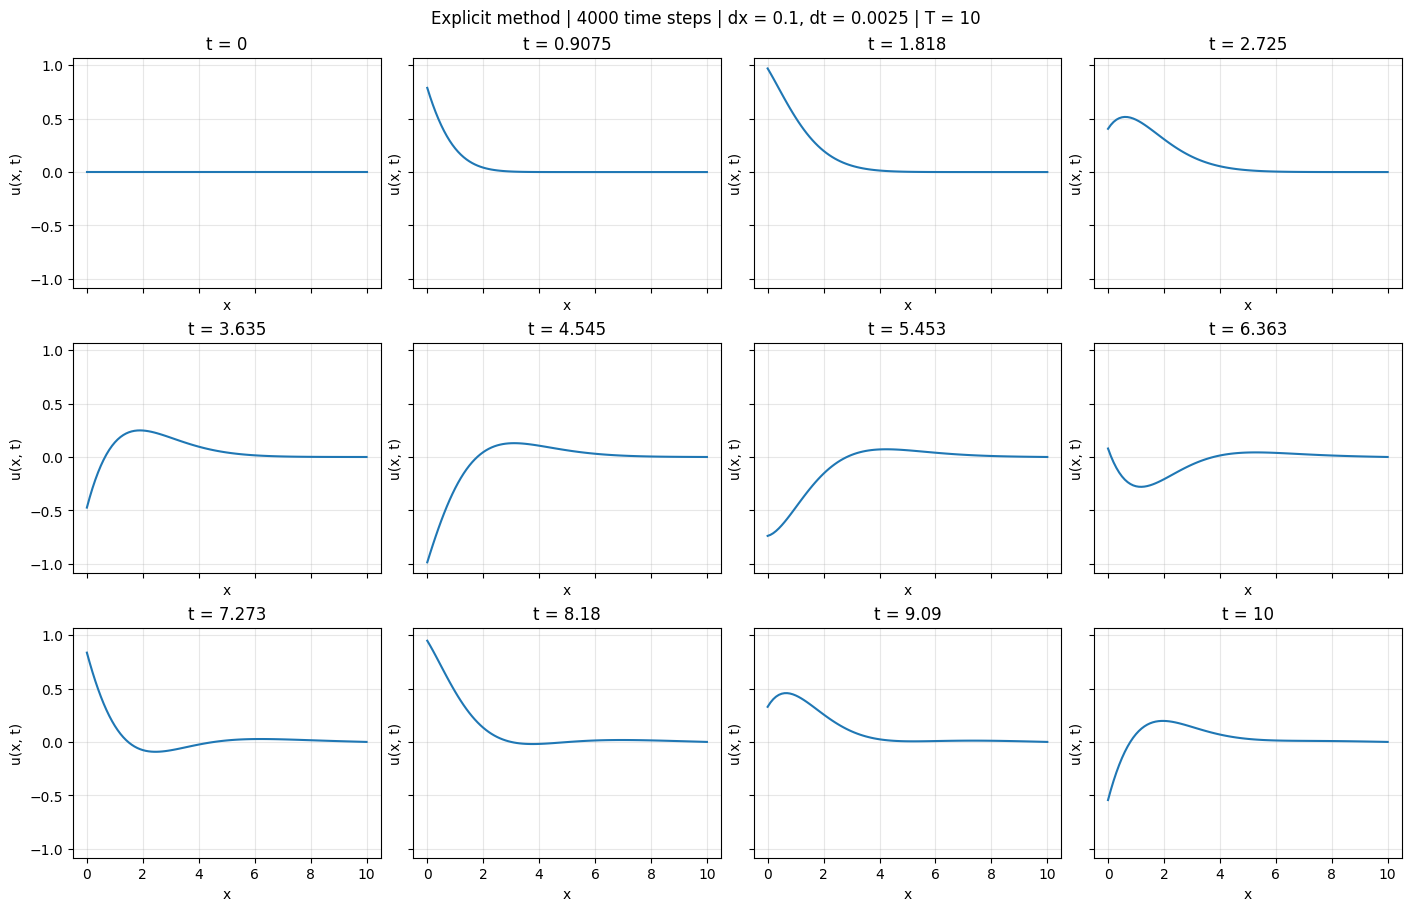

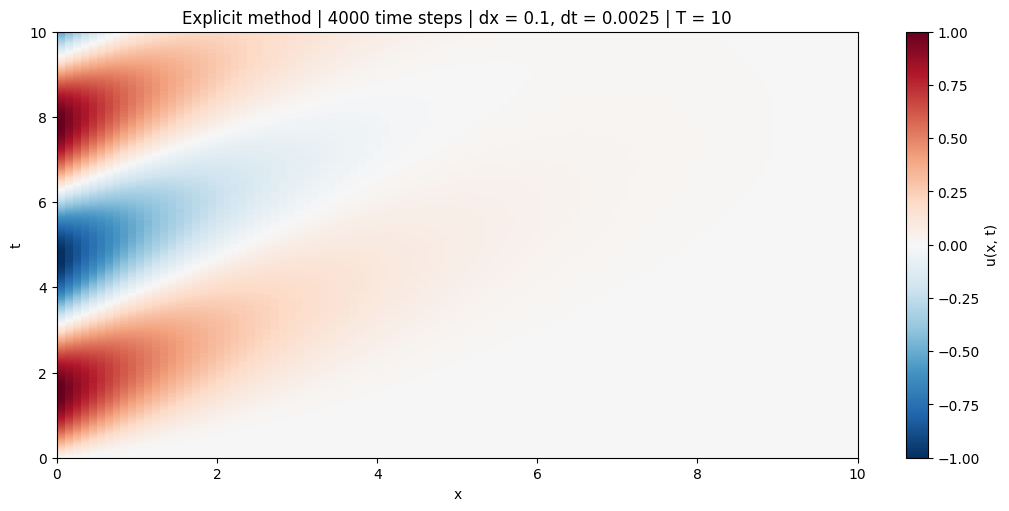

In [3]:
explicit_01 = solve_heat(dx=0.1, steps=4000, method="explicit")

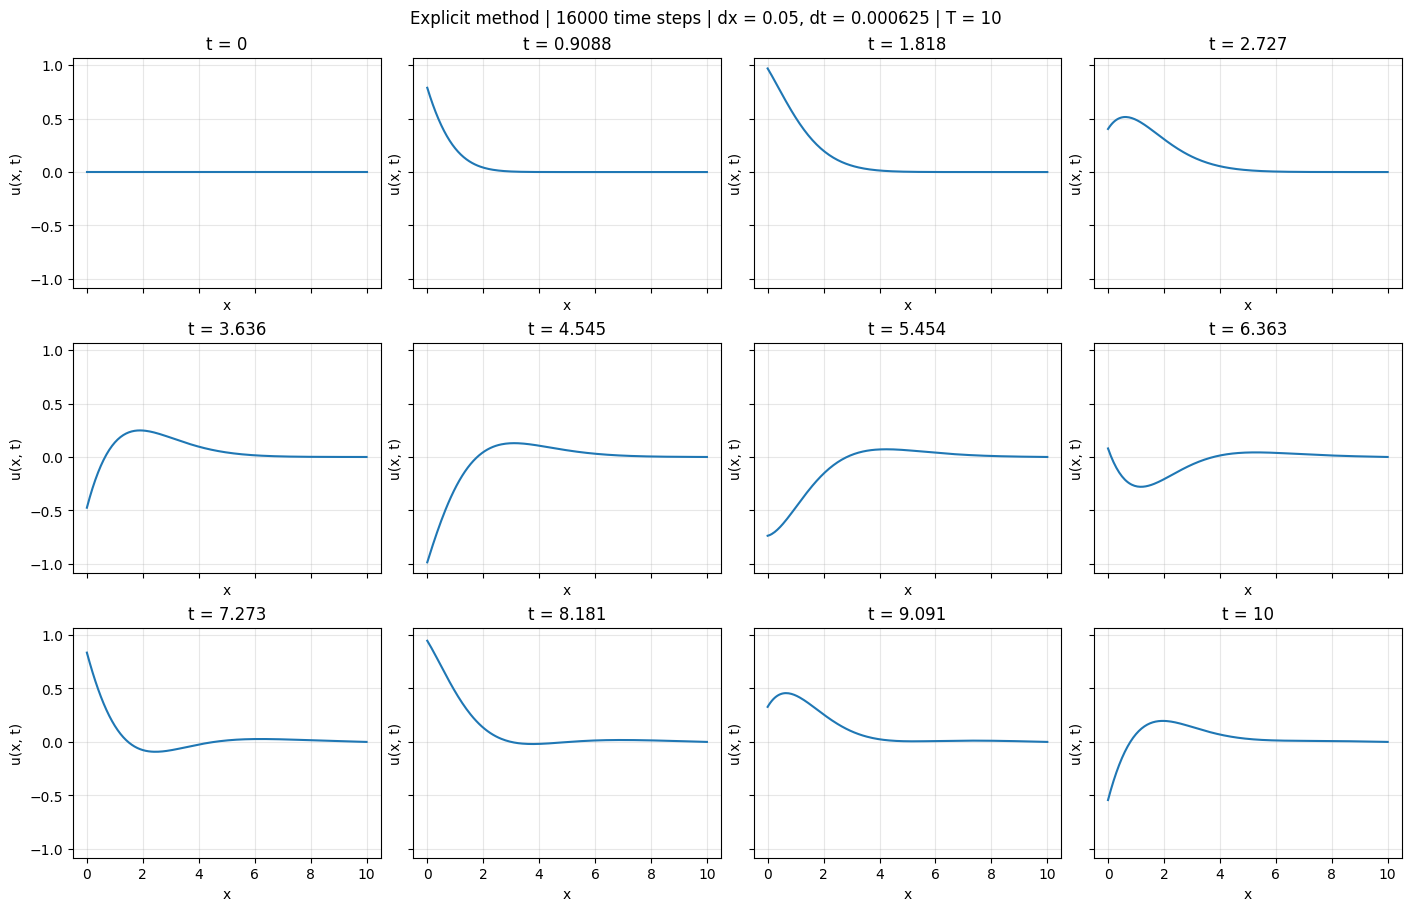

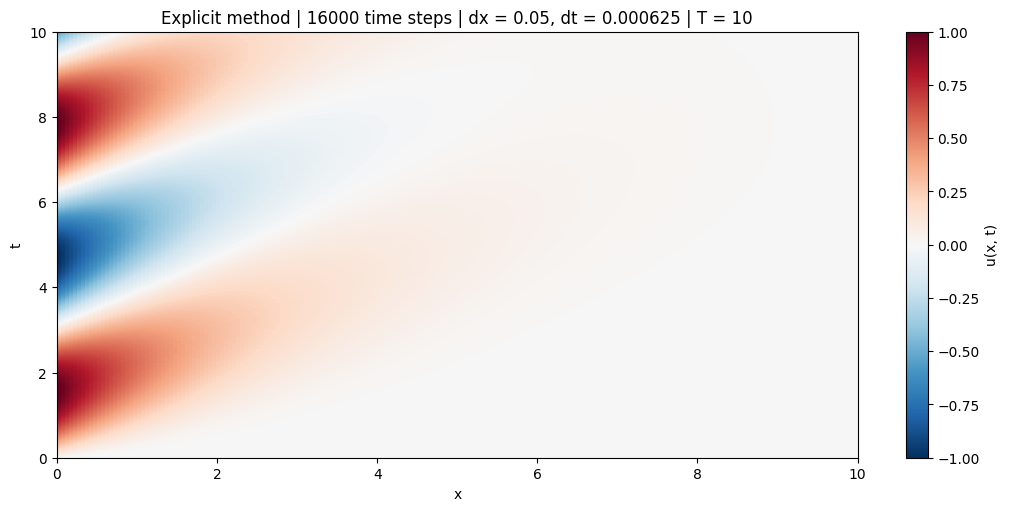

In [4]:
explicit_005 = solve_heat(dx=0.05, steps=16000, method="explicit")

#### Implicit Method:

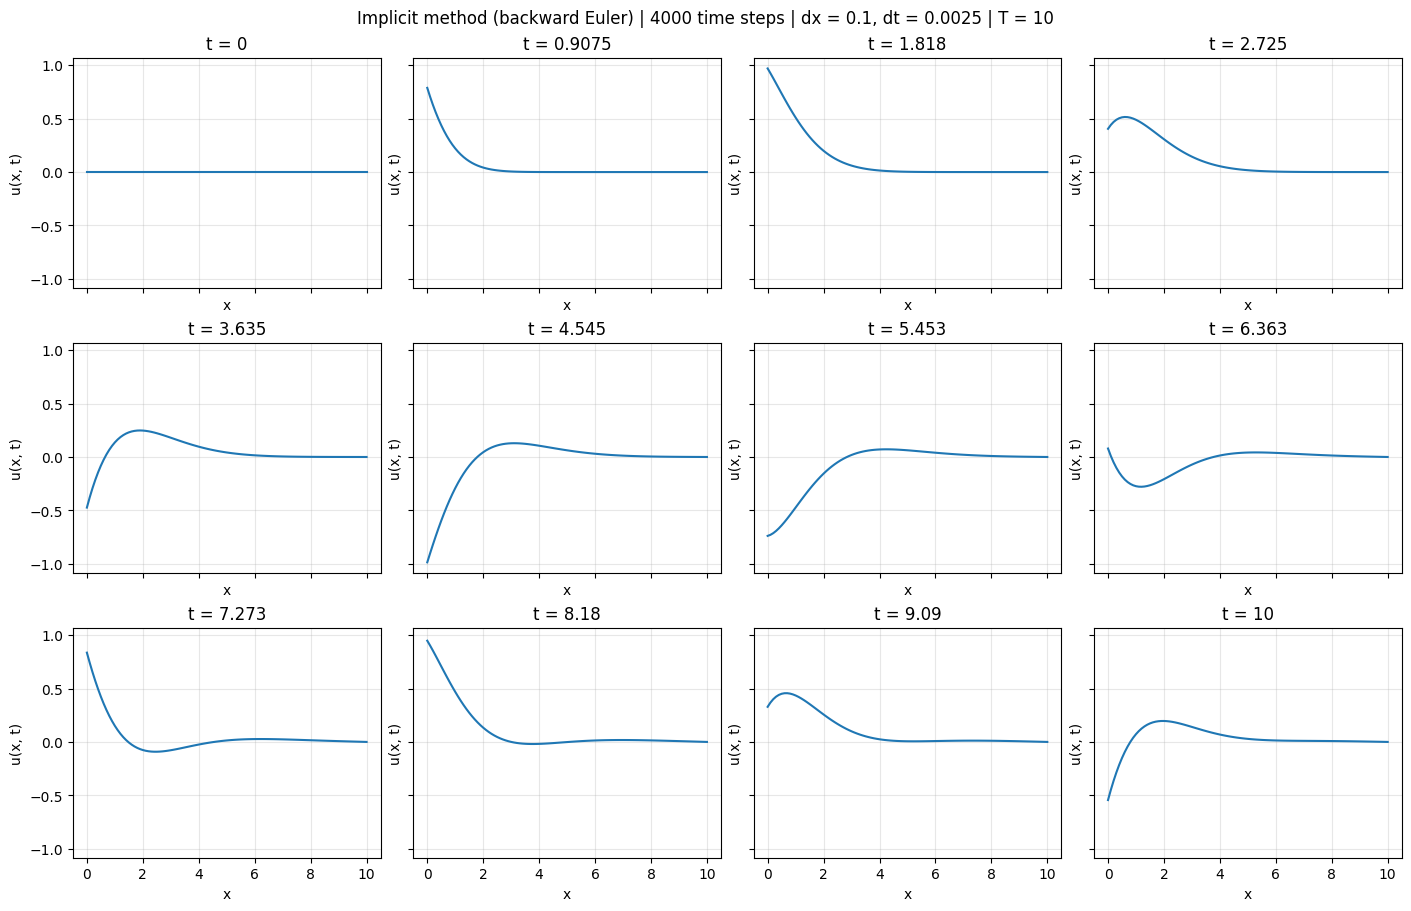

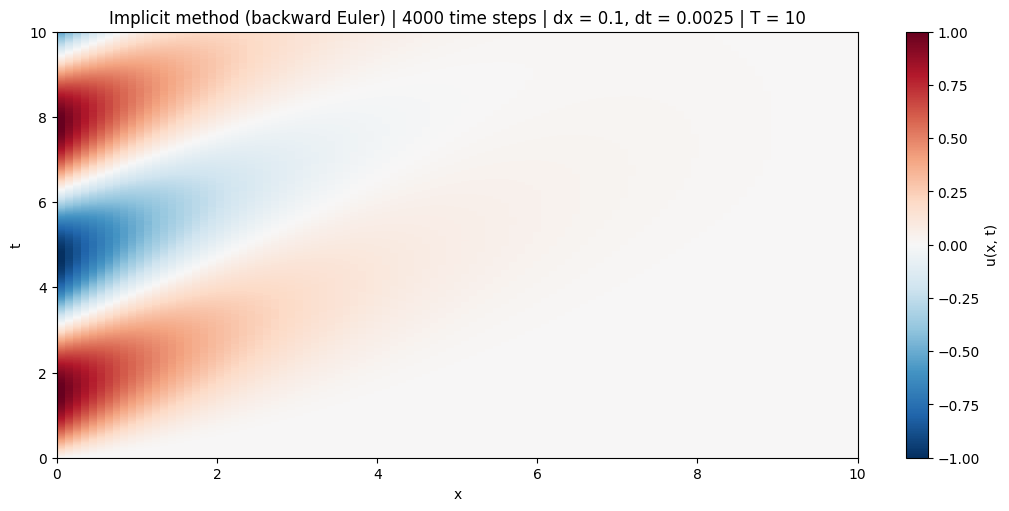

In [5]:
implicit_01 = solve_heat(dx=0.1, steps=4000, method="implicit")

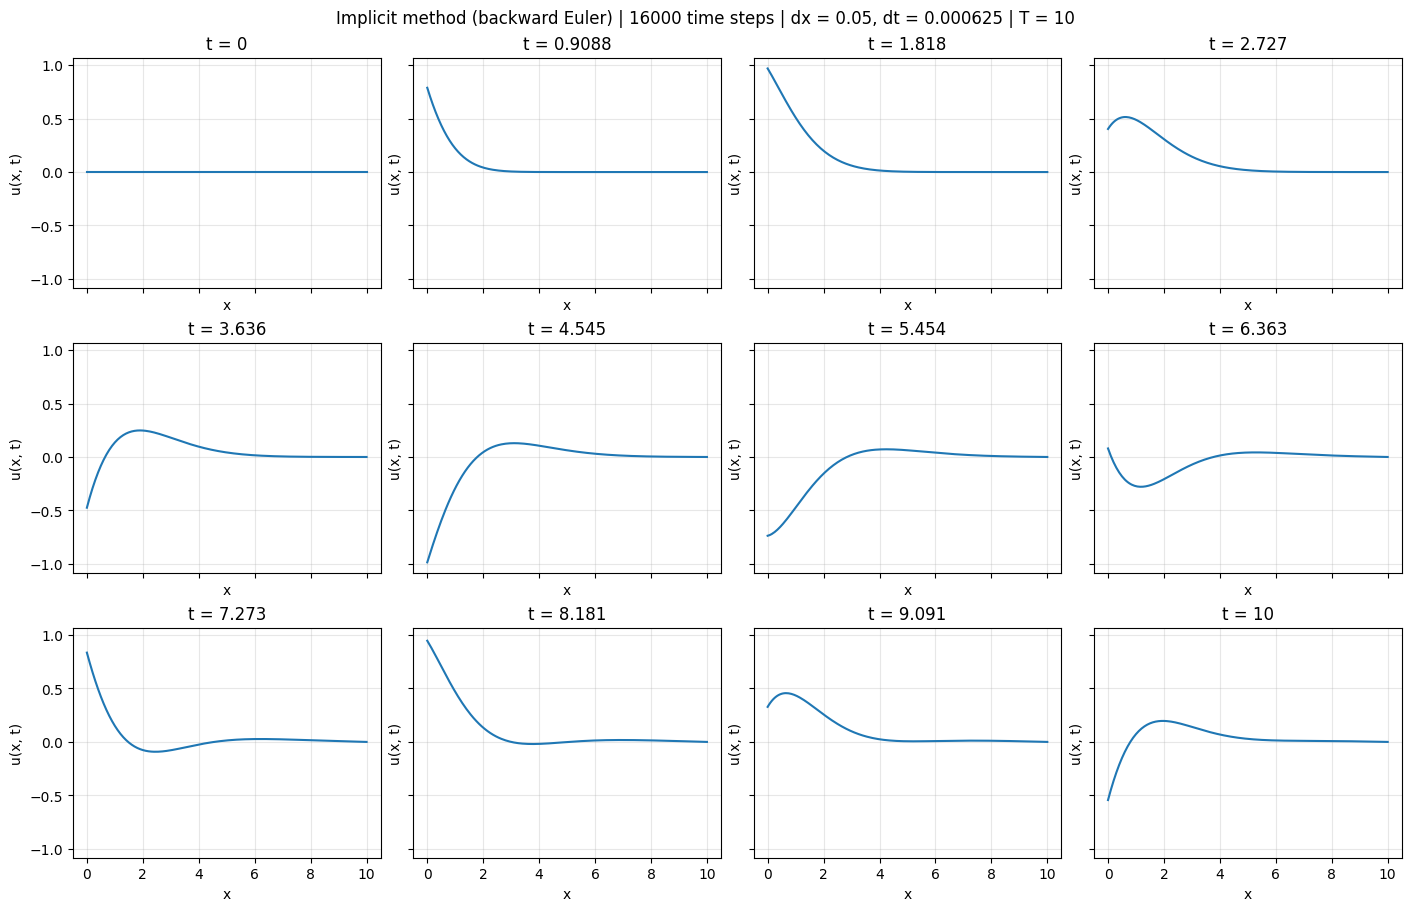

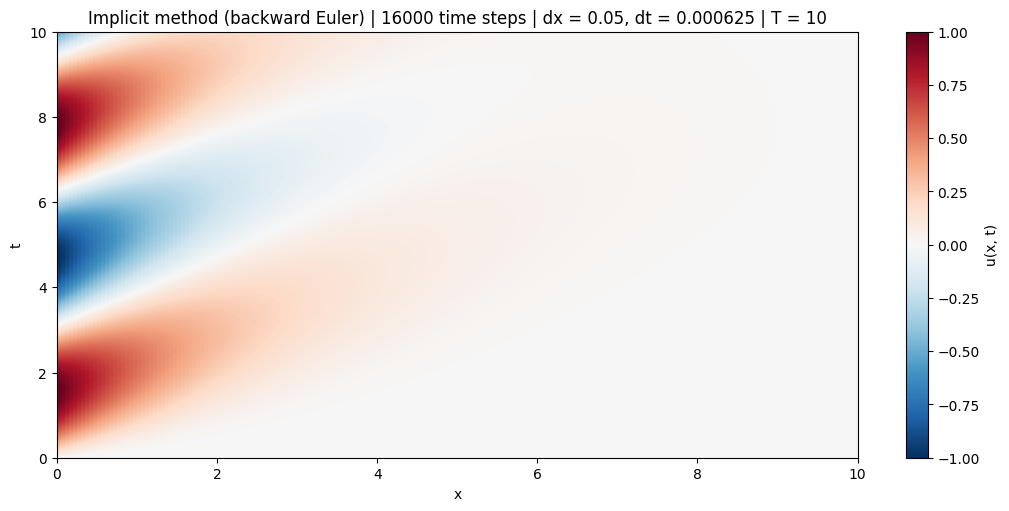

In [6]:
implicit_005 = solve_heat(dx=0.05, steps=16000, method="implicit")

### Problem 2

Same problem above but now $u(0,t)=\text{sin}(\pi t)$ and $u(10,t)=\text{sin}(\sqrt{2} \pi t)$

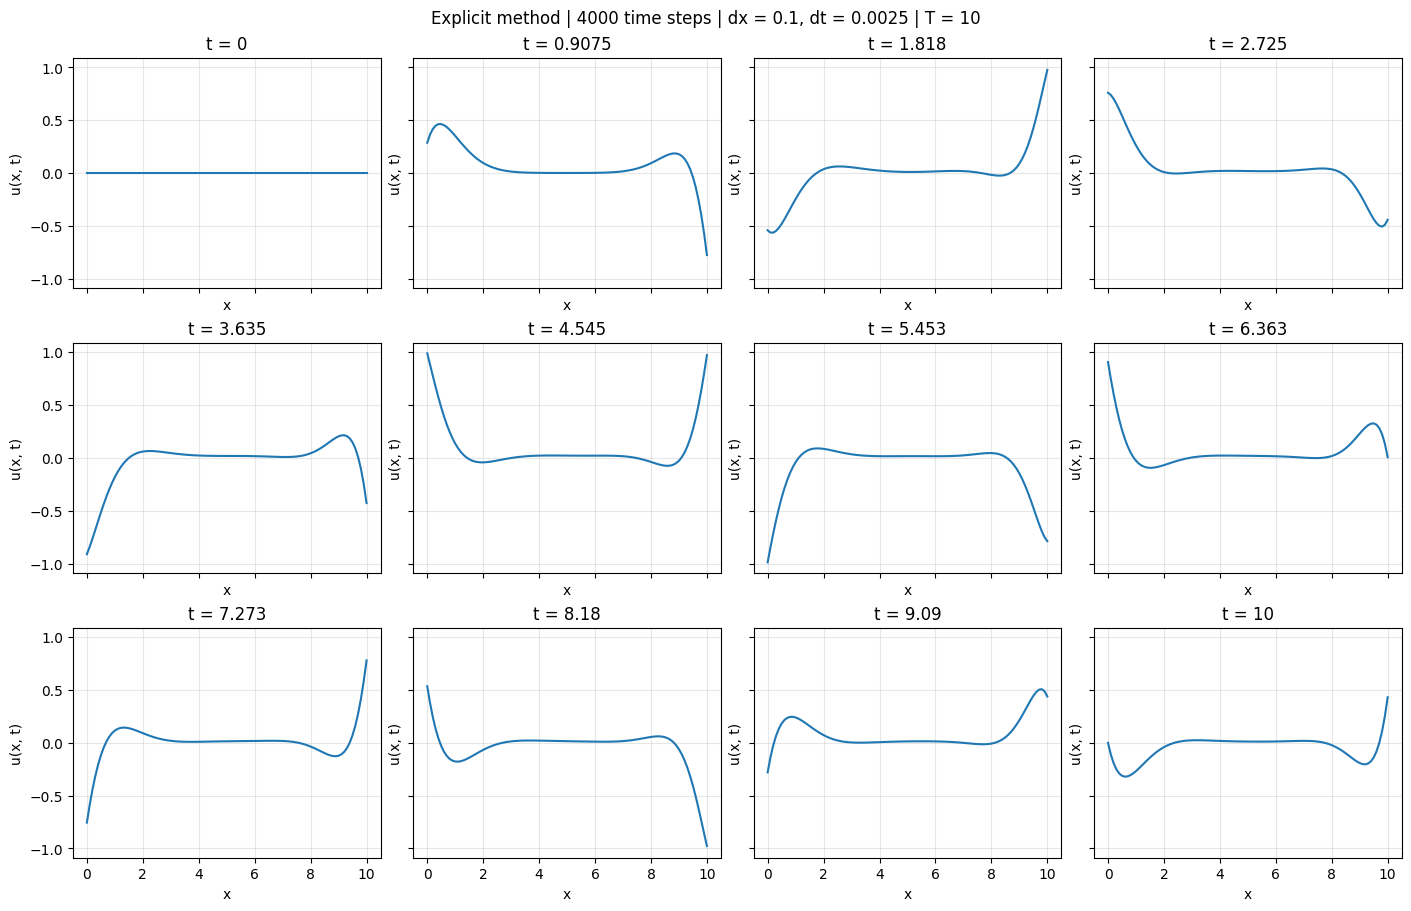

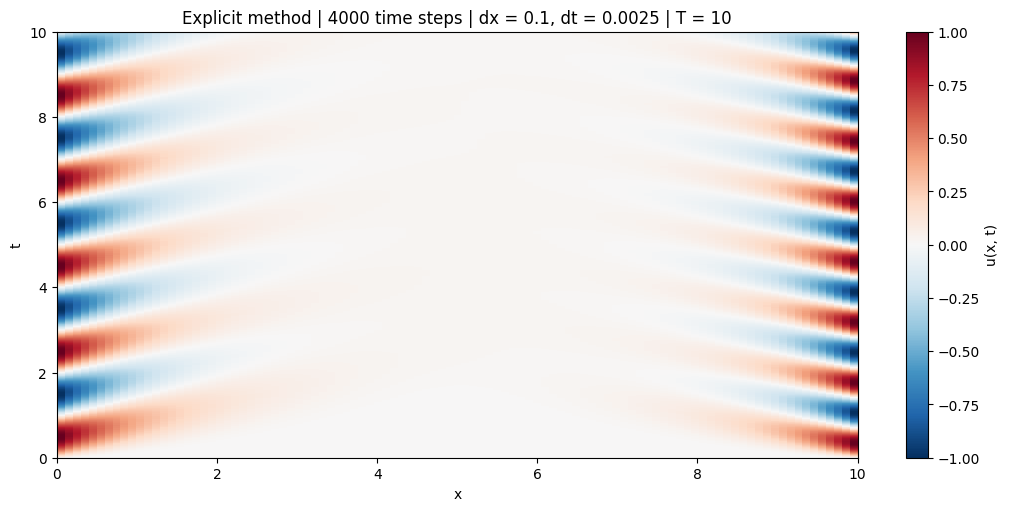

In [7]:
problem2 = solve_heat(
    dx=0.1,
    steps=4000,
    method="explicit",
    alpha=lambda t: np.sin(np.pi * t),
    beta=lambda t: np.sin(np.sqrt(2) * np.pi * t),
)

### Problem 3

h=1e-01: approx=5.192, error=2.446e-01
h=1e-02: approx=5.435, error=1.865e-03
h=1e-03: approx=5.437, error=1.817e-05


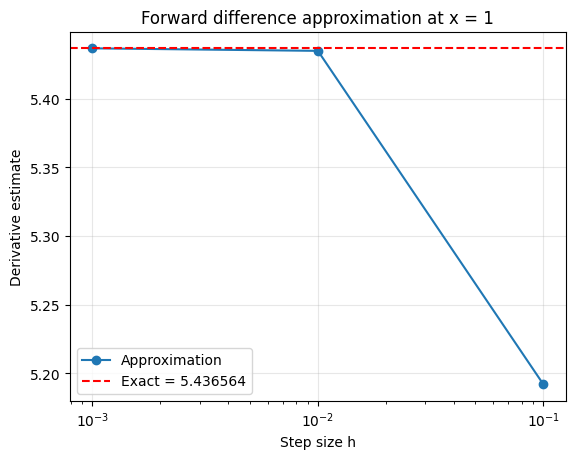

In [8]:
f = lambda x: np.exp(x**2)

def approx_derivative(x, h):
    return (-f(x + 2*h) + 4*f(x + h) - 3*f(x)) / (2*h)

x = 1
h_values = np.array([1e-1, 1e-2, 1e-3])

estimates = approx_derivative(x, h_values)
exact = 2 * x * f(x)
errors = np.abs(estimates - exact)

for h, estimate, error in zip(h_values, estimates, errors):
    print(f"h={h:.0e}: approx={estimate:.3f}, error={error:.3e}")

plt.plot(h_values, estimates, "o-", label="Approximation")
plt.axhline(exact, color="red", linestyle="--",
            label=f"Exact = {exact:.6f}")
plt.xscale("log")
plt.xlabel("Step size h")
plt.ylabel("Derivative estimate")
plt.title("Forward difference approximation at x = 1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Problem 4

Now we modify to Neumann boundary conditions:

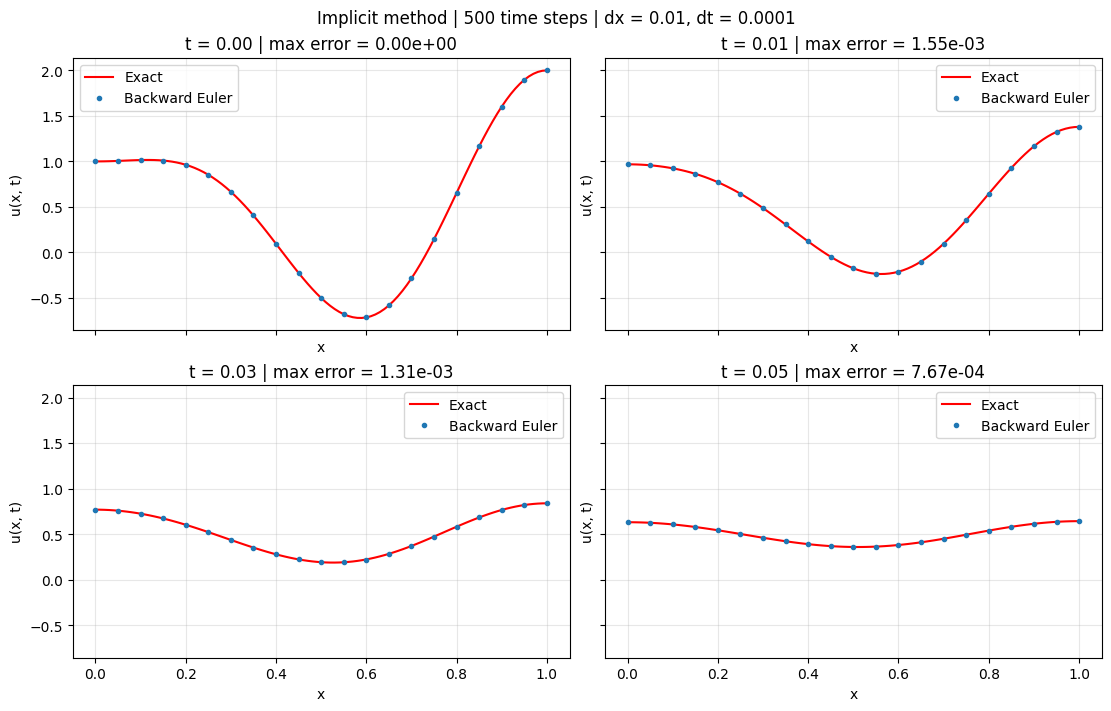

In [9]:
def exact_solution(x, t):
    return (
        0.5
        + np.exp(-4*np.pi**2*t) * np.cos(2*np.pi*x)
        - 0.5*np.exp(-9*np.pi**2*t) * np.cos(3*np.pi*x)
    )

dx, dt = 0.01, 0.0001
steps = 500
mu = dt / dx**2

x = np.arange(0, 1 + dx/2, dx)
N = len(x) - 1

main = np.full(N + 1, 1 + 2*mu)
lower = np.full(N, -mu)
upper = np.full(N, -mu)

# Zero Neumann conditions, using reflected auxiliary points
upper[0] = -2*mu
lower[-1] = -2*mu

A = diags_array(
    [lower, main, upper],
    offsets=[-1, 0, 1],
    format="csc",
)
solve = factorized(A)

# Initial condition and snapshots
u = exact_solution(x, 0)
snapshot_steps = [0, 100, 300, 500]
solutions = {0: u.copy()}

for n in range(1, steps + 1):
    u = solve(u)
    if n in snapshot_steps:
        solutions[n] = u.copy()

# Compare numerical and exact solutions
fig, axes = plt.subplots(
    2, 2, figsize=(11, 7),
    sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, n in zip(axes.flat, snapshot_steps):
    t = n * dt
    exact = exact_solution(x, t)
    error = np.max(np.abs(solutions[n] - exact))

    ax.plot(x, exact, "r-", label="Exact")
    ax.plot(
        x, solutions[n], "o",
        markevery=5, markersize=3,
        label="Backward Euler",
    )
    ax.set_title(f"t = {t:.2f} | max error = {error:.2e}")
    ax.set_xlabel("x")
    ax.set_ylabel("u(x, t)")
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    f"Implicit method | {steps} time steps | dx = {dx}, dt = {dt}"
)
plt.show()